# Selección de características con metaheurísticas

**Aplicación de metaheurísticas a Machine Learning (2/2)** · el individuo es un vector binario: ¿qué variables entran al modelo?

Si en la [notebook 16](16-hiperparametros-ml-metaheuristicas.ipynb) el individuo era un vector de hiperparámetros, aquí es una **máscara binaria** $x\in\{0,1\}^p$. Es un problema combinatorio clásico (espacio de $2^p$ subconjuntos) con un fitness caro y ruidoso (entrenar un modelo con las variables elegidas), de modo que es el terreno natural de los algoritmos genéticos, PSO binario, recocido simulado y búsqueda local por *bit-flip*.

**Tabla de contenido**

1. Marco: selección de características como optimización binaria (filtro, wrapper, embebido)
2. Datos: un problema con verdad conocida (informativas, redundantes, ruido)
3. Fitness: error de validación + penalización por parsimonia, y un evaluador rápido y verificado
4. Validación del enfoque en un caso pequeño con búsqueda exhaustiva
5. Los optimizadores binarios desde cero (búsqueda local *bit-flip*, SA, AG binario, PSO binario, (1+1)-EA)
6. Líneas base: filtros (correlación, información mutua), Lasso y RFE
7. Experimento: recuperación de las variables verdaderas y significancia
8. Frente de Pareto: precisión vs parsimonia
9. Aplicación a la serie de demanda eléctrica con rezagos candidatos
10. Selección simultánea de características e hiperparámetros (individuo mixto)
11. Ventajas, limitaciones, resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Qué vas a aprender**

- Formular la selección de variables como optimización binaria con fitness $=$ error de validación $+$ penalización por nº de variables.
- Implementar y comparar con el **mismo presupuesto**: AG binario, PSO binario (sigmoide), recocido simulado, búsqueda local de *bit-flip* con reinicios y $(1+1)$-EA.
- Compararlos con filtros (correlación, información mutua), **Lasso** (selección embebida) y **RFE**.
- Medir si se **recuperan las variables verdaderamente informativas** (precisión, recall, ruido colado) en datos donde se conoce la verdad.
- Trazar el **frente de Pareto** error vs número de variables y entender el papel del peso de la penalización.
- Resolver conjuntamente selección de variables **e hiperparámetros** con un individuo mixto (bits + genes continuos).

**Prerrequisitos**: [09 · algoritmos genéticos](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb), [11 · PSO](../03-metodos-poblacionales/11-enjambre-pso-evolucion-diferencial.ipynb), [05 · recocido simulado](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb), [03 · búsqueda local](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb), [12 · multiobjetivo](../04-topicos-avanzados/12-optimizacion-multiobjetivo.ipynb) y la notebook [16](16-hiperparametros-ml-metaheuristicas.ipynb) (evaluador con caché y diseño experimental).

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge, LassoCV, LinearRegression
from sklearn.feature_selection import mutual_info_regression, RFE
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

threadpool_limits(1)
warnings.filterwarnings("ignore")
SEMILLA = 7
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Listo. Semilla:", SEMILLA)

Listo. Semilla: 7


## 1. Marco: selección de características como optimización binaria

Dado un conjunto de $p$ variables candidatas, se busca el subconjunto $S\subseteq\{1,\dots,p\}$ que mejor sirva a un modelo. Con la codificación binaria $x_j=1\iff j\in S$:

$$
\min_{x\in\{0,1\}^p}\; F(x)\;=\;\underbrace{\text{err}_{\text{val}}\big(\mathcal{A}(\mathcal{D}_{\text{train}}[:,S_x])\big)}_{\text{ajuste}}\;+\;\lambda\,\underbrace{\frac{\lVert x\rVert_1}{p}}_{\text{parsimonia}},\qquad \lambda\ge 0 .
$$

El primer término se evalúa **entrenando el modelo** (estrategia *wrapper*); el segundo castiga complejidad. Interpretar $\lambda$ como el "precio" de una variable: una variable entra solo si reduce el error relativo en más de $\lambda/p$. Es una **escalarización** del problema bi-objetivo (error, tamaño); el frente de Pareto de la sección 8 muestra qué se pierde al fijar $\lambda$.

### Tres familias de métodos

| Familia | Cómo decide | Ejemplos | Ventaja | Limitación |
|---|---|---|---|---|
| **Filtro** | Puntúa cada variable por separado, sin modelo (o con uno trivial) | correlación, información mutua | Muy barato, independiente del modelo | Ignora interacciones y redundancia; elegir $k$ es aparte |
| **Embebido** | La selección ocurre dentro del entrenamiento | Lasso ($\ell_1$), importancias de árboles | Barato, una sola corrida | Atado a un modelo y a su sesgo (p. ej. Lasso es lineal) |
| **Wrapper** | Evalúa subconjuntos entrenando el modelo objetivo | RFE, metaheurísticas (este notebook) | Considera interacciones y optimiza la métrica *real* | Costoso; riesgo de sobreajuste al conjunto de validación |

### Tamaño del espacio y por qué metaheurísticas

Hay $2^p$ subconjuntos: $2^{20}\approx10^6$, $2^{30}\approx10^9$, $2^{100}\approx10^{30}$. La búsqueda exhaustiva es viable hasta $p\approx 20$ si evaluar es barato. Más allá, las metaheurísticas buscan buenos subconjuntos con $B\ll 2^p$ evaluaciones. El vecindario natural es el **bit-flip** (agregar o quitar una variable): cada solución tiene exactamente $p$ vecinos, y la distancia de Hamming mide qué tan "lejos" están dos subconjuntos.

### Precauciones metodológicas

1. **Fuga de información**: la selección debe hacerse **solo con datos de entrenamiento/validación**; elegir variables con todo el conjunto y luego hacer validación cruzada da errores optimistas.
2. **Optimismo de la selección**: igual que en HPO ([16 · §11](16-hiperparametros-ml-metaheuristicas.ipynb)), el mejor subconjunto sobre validación está sesgado a la baja; se reserva un **conjunto de prueba intacto**.
3. **Estabilidad**: con datos finitos, corridas distintas pueden devolver subconjuntos distintos; se mide con la *frecuencia de selección* de cada variable.
4. **Variables correlacionadas**: si dos variables son casi intercambiables, cualquiera de las dos es una solución legítima: "recuperar la verdad" debe tolerar redundancia.

## 2. Datos: un problema con verdad conocida

Para poder *verificar* la recuperación de variables construimos un conjunto de $p=50$ columnas con tres tipos de variables, mezcladas al azar:

- **Informativas (8)**: generadas con `make_regression` (el objetivo es una combinación lineal de ellas más ruido). Sus coeficientes son muy desiguales, así que algunas aportan poca varianza.
- **Redundantes (8)**: combinaciones lineales ruidosas de las informativas. Son útiles pero *sustituibles*.
- **Ruido (34)**: gaussianas independientes de $y$.

Que las informativas tengan coeficientes de magnitud distinta es deliberado: una variable que aporta menos varianza que el costo $\lambda/p$ de incluirla **no debería** ser seleccionada por un fitness penalizado. Definimos como **relevantes** las informativas que aportan al menos el 1% de la varianza de $y$.

X: (700, 50) | y: media=-7.6, desv=181.7
Informativas y su aporte relativo a la varianza de y:
   x01: aporte=  9.4%   (relevante)
   x24: aporte= 16.8%   (relevante)
   x37: aporte=  3.9%   (relevante)
   x38: aporte= 23.9%   (relevante)
   x39: aporte=  0.3%   (aporte < 1%)
   x41: aporte= 26.4%   (relevante)
   x45: aporte=  6.1%   (relevante)
   x47: aporte=  9.7%   (relevante)
Variables relevantes (verdad a recuperar): ['x01', 'x24', 'x37', 'x38', 'x41', 'x45', 'x47']


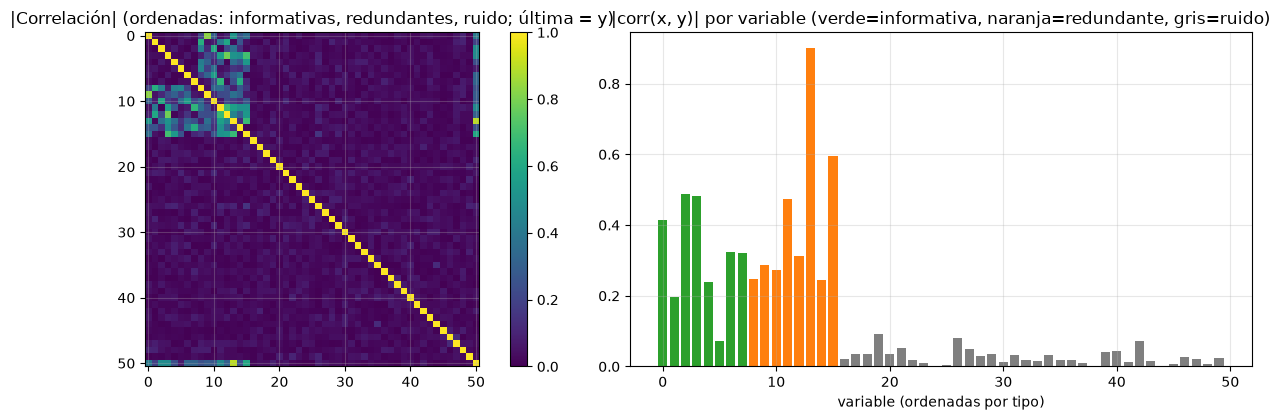

In [2]:
def crear_datos(n=700, seed=SEMILLA):
    rng = np.random.default_rng(seed)
    X_inf, y, coef = make_regression(n_samples=n, n_features=8, n_informative=8, noise=40.0, shuffle=False,
                                     coef=True, random_state=seed)
    W = rng.normal(size=(8, 8))
    X_red = X_inf @ W + 0.3 * rng.normal(size=(n, 8)) * X_inf.std(0).mean()      # redundantes
    X_ruido = rng.normal(size=(n, 34))
    X = np.hstack([X_inf, X_red, X_ruido])
    tipo = np.array(["informativa"] * 8 + ["redundante"] * 8 + ["ruido"] * 34)
    perm = rng.permutation(X.shape[1])                                           # mezclar: la posición no delata el tipo
    return X[:, perm], y, tipo[perm], coef, perm

X, y, tipo, coef, perm = crear_datos()
p = X.shape[1]
nombres = np.array([f"x{j:02d}" for j in range(p)])
varianza_aporte = np.zeros(p)
for k in range(8):                                  # columnas informativas originales: 0..5 -> posición tras la permutación
    j = int(np.where(perm == k)[0][0]); varianza_aporte[j] = coef[k] ** 2 * X[:, j].var() / y.var()
relevante = (tipo == "informativa") & (varianza_aporte >= 0.01)
print(f"X: {X.shape} | y: media={y.mean():.1f}, desv={y.std():.1f}")
print("Informativas y su aporte relativo a la varianza de y:")
for j in np.where(tipo == "informativa")[0]:
    print(f"   {nombres[j]}: aporte={100 * varianza_aporte[j]:5.1f}%   {'(relevante)' if relevante[j] else '(aporte < 1%)'}")
print("Variables relevantes (verdad a recuperar):", nombres[relevante].tolist())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
orden = np.argsort([{"informativa": 0, "redundante": 1, "ruido": 2}[t] for t in tipo])
im = ax[0].imshow(np.abs(np.corrcoef(np.column_stack([X[:, orden], y]).T)), cmap="viridis", vmin=0, vmax=1)
ax[0].set_title("|Correlación| (ordenadas: informativas, redundantes, ruido; última = y)"); plt.colorbar(im, ax=ax[0])
corr_y = np.abs([np.corrcoef(X[:, j], y)[0, 1] for j in range(p)])
colores = {"informativa": "tab:green", "redundante": "tab:orange", "ruido": "tab:gray"}
ax[1].bar(range(p), corr_y[orden], color=[colores[tipo[j]] for j in orden])
ax[1].set_title("|corr(x, y)| por variable (verde=informativa, naranja=redundante, gris=ruido)"); ax[1].set_xlabel("variable (ordenadas por tipo)")
plt.tight_layout(); plt.show()

## 3. Fitness: error de validación + penalización, y un evaluador rápido

El modelo del *wrapper* es **regresión Ridge** con un $\alpha$ pequeño fijo: es un modelo cuyo ajuste tiene forma cerrada, de modo que cada evaluación cuesta microsegundos y podemos hacer miles de ellas en todos los métodos, con múltiples réplicas. (En un modelo caro la historia es la de la notebook 16: el presupuesto es lo que manda.) Con $G=X_S^\top X_S$ y $b=X_S^\top y$ sobre el bloque de entrenamiento de cada pliegue,

$$
w_S=(G_{SS}+\alpha I)^{-1}b_S,\qquad \hat y = X^{\text{val}}_S w_S + \bar y .
$$

Los productos $G$ y $b$ se calculan **una sola vez por pliegue**; evaluar un subconjunto solo resuelve un sistema $k\times k$. El error es el RMSE de validación **relativo** a la desviación de $y$, promediado sobre pliegues (validación cruzada para datos iid; pliegues de ventana creciente en series de tiempo). Los datos de prueba nunca entran.

La **evaluación** incluye una caché por máscara (misma idea que en la notebook 16): evaluar dos veces la misma máscara no consume presupuesto.

In [3]:
class Agotado(Exception):
    pass

def crear_pliegues(Xm, ym, pliegues):
    """Precalcula, por pliegue, Gram y b del entrenamiento (estandarizado con estadísticos del propio entrenamiento)."""
    out = []
    for tr, va in pliegues:
        mu, sd = Xm[tr].mean(0), Xm[tr].std(0) + 1e-12
        Xt, Xv = (Xm[tr] - mu) / sd, (Xm[va] - mu) / sd
        ymu = ym[tr].mean()
        out.append({"G": Xt.T @ Xt, "b": Xt.T @ (ym[tr] - ymu), "Xv": Xv, "yv": ym[va], "ymu": ymu})
    return out

class Wrapper:
    """Fitness de un subconjunto: RMSE relativo medio de validación (CV) + lambda * k / p."""
    def __init__(self, Xm, ym, pliegues, lam=0.02, alpha=1e-2):
        self.p, self.lam, self.alpha = Xm.shape[1], lam, alpha
        self.F = crear_pliegues(Xm, ym, pliegues); self.ystd = ym.std()
    def error(self, mask):
        S = np.flatnonzero(mask)
        if len(S) == 0:                                   # modelo vacío: predice la media
            return float(np.mean([np.sqrt(np.mean((f["yv"] - f["ymu"]) ** 2)) for f in self.F]) / self.ystd)
        errs = []
        for f in self.F:
            G = f["G"][np.ix_(S, S)] + self.alpha * np.eye(len(S))
            w = np.linalg.solve(G, f["b"][S])
            errs.append(np.sqrt(np.mean((f["yv"] - (f["Xv"][:, S] @ w + f["ymu"])) ** 2)))
        return float(np.mean(errs) / self.ystd)
    def fitness(self, mask):
        return self.error(mask) + self.lam * np.sum(mask) / self.p

class Evaluador:
    """Memoiza por máscara, cobra solo evaluaciones nuevas, guarda archivo (k, error) y curva de convergencia."""
    def __init__(self, wrap, presupuesto):
        self.w, self.B = wrap, presupuesto
        self.cache, self.usado, self.llamadas = {}, 0, 0
        self.hist, self.mejor_f, self.mejor_x = [], np.inf, None
        self.archivo = []
    def __call__(self, x):
        x = np.asarray(x, dtype=np.int8)
        if self.usado >= self.B or self.llamadas > 60 * self.B: raise Agotado
        self.llamadas += 1
        k = x.tobytes()
        if k in self.cache: return self.cache[k]
        e = self.w.error(x); f = e + self.w.lam * x.sum() / self.w.p
        self.cache[k] = f; self.usado += 1; self.archivo.append((int(x.sum()), e))
        if f < self.mejor_f: self.mejor_f, self.mejor_x = f, x.copy()
        self.hist.append(self.mejor_f)
        return f

# datos iid: 500 para validación cruzada (selección) y 200 de prueba intactos
rng_s = np.random.default_rng(SEMILLA)
idx = rng_s.permutation(len(y)); i_sel, i_te = idx[:500], idx[500:]
folds = np.array_split(np.arange(len(i_sel)), 5)
pliegues_iid = [(np.concatenate([folds[j] for j in range(5) if j != i]), folds[i]) for i in range(5)]
W_iid = Wrapper(X[i_sel], y[i_sel], pliegues_iid, lam=0.02)

# --- verificación contra scikit-learn (el evaluador rápido debe coincidir con Ridge del manual) ---
mask_t = (np.random.default_rng(3).random(p) < 0.4).astype(np.int8); S_t = np.flatnonzero(mask_t)
errs = []
for tr, va in pliegues_iid:
    Xm_, ym_ = X[i_sel], y[i_sel]; mu, sd = Xm_[tr][:, S_t].mean(0), Xm_[tr][:, S_t].std(0) + 1e-12
    m = Ridge(alpha=1e-2).fit((Xm_[tr][:, S_t] - mu) / sd, ym_[tr])
    errs.append(np.sqrt(np.mean((ym_[va] - m.predict((Xm_[va][:, S_t] - mu) / sd)) ** 2)))
ref = np.mean(errs) / y[i_sel].std()
print(f"error evaluador rápido = {W_iid.error(mask_t):.6f} | error con sklearn.Ridge = {ref:.6f}")
assert abs(W_iid.error(mask_t) - ref) < 1e-8
t0 = time.perf_counter(); [W_iid.fitness(mask_t) for _ in range(2000)]
print(f"Costo medio por evaluación: {(time.perf_counter() - t0) / 2000 * 1e6:.0f} microsegundos")

error evaluador rápido = 0.309408 | error con sklearn.Ridge = 0.309408


Costo medio por evaluación: 99 microsegundos


## 4. Validación del enfoque con búsqueda exhaustiva (caso pequeño)

Antes de confiar en una metaheurística conviene saber *a dónde debería llegar*. Con $p=14$ variables hay $2^{14}=16384$ subconjuntos, y podemos evaluarlos todos. Usamos las 6 informativas de mayor aporte, 3 redundantes y 5 de ruido del problema anterior, y obtenemos el **óptimo global** del fitness penalizado. Esto sirve para dos cosas: (i) comprobar si las variables que el óptimo exhaustivo elige coinciden con las relevantes; (ii) más adelante, verificar que las metaheurísticas llegan a ese óptimo.

Búsqueda exhaustiva de 16384 subconjuntos en 2.0s
Óptimo global (fitness): 0.23457 | variables elegidas: ['x41', 'x38', 'x24', 'x47', 'x01', 'x45', 'x03', 'x06']
Tipos de las elegidas: {'informativa': np.int64(6), 'redundante': np.int64(2)}
Relevantes del subproblema: ['x41', 'x38', 'x24', 'x47', 'x01', 'x45']


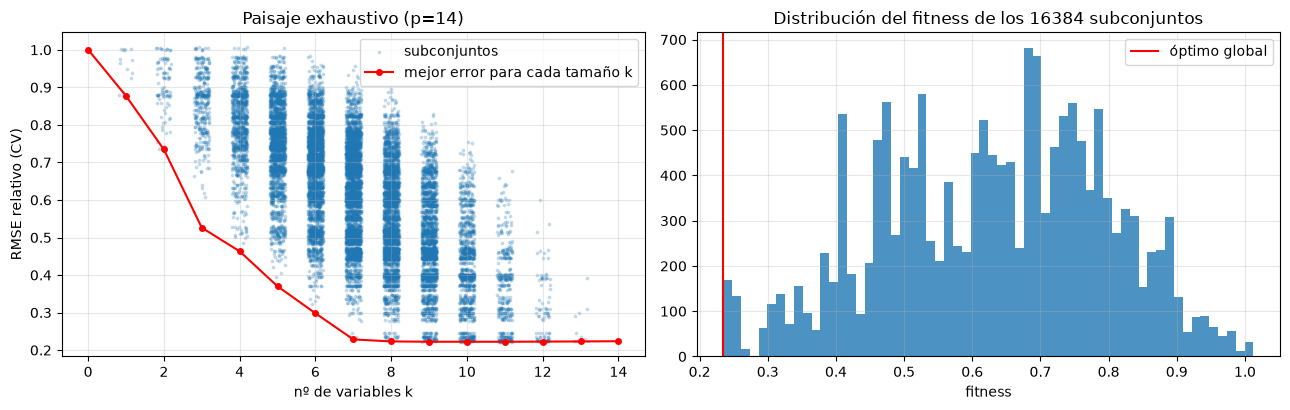

In [4]:
# subproblema: las 6 informativas de mayor aporte + 3 redundantes + 5 ruido = 14 variables
rng_p = np.random.default_rng(11)
cols = np.concatenate([np.where(tipo == "informativa")[0][np.argsort(-varianza_aporte[tipo == "informativa"])[:6]], np.where(tipo == "redundante")[0][:3], np.where(tipo == "ruido")[0][:5]])
W14 = Wrapper(X[i_sel][:, cols], y[i_sel], pliegues_iid, lam=0.02)
t0 = time.perf_counter()
todas = ((np.arange(2 ** 14)[:, None] >> np.arange(14)) & 1).astype(np.int8)
F_todas = np.array([W14.fitness(m) for m in todas]); E_todas = np.array([W14.error(m) for m in todas])
k_todas = todas.sum(1)
print(f"Búsqueda exhaustiva de {len(todas)} subconjuntos en {time.perf_counter() - t0:.1f}s")
j_opt = int(np.argmin(F_todas)); opt14 = todas[j_opt]
print("Óptimo global (fitness):", round(F_todas[j_opt], 5), "| variables elegidas:", nombres[cols][opt14 == 1].tolist())
print("Tipos de las elegidas:", dict(pd.Series(tipo[cols][opt14 == 1]).value_counts()))
print("Relevantes del subproblema:", nombres[cols][relevante[cols]].tolist())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(k_todas + np.random.default_rng(0).uniform(-0.2, 0.2, len(k_todas)), E_todas, s=3, alpha=0.2, label="subconjuntos")
mejor_k = [E_todas[k_todas == k].min() for k in range(15)]
ax[0].plot(range(15), mejor_k, "r-o", ms=4, label="mejor error para cada tamaño k")
ax[0].set_xlabel("nº de variables k"); ax[0].set_ylabel("RMSE relativo (CV)"); ax[0].set_title("Paisaje exhaustivo (p=14)"); ax[0].legend()
ax[1].hist(F_todas, bins=60, color="tab:blue", alpha=0.8); ax[1].axvline(F_todas[j_opt], color="r", label="óptimo global")
ax[1].set_xlabel("fitness"); ax[1].set_title("Distribución del fitness de los 16384 subconjuntos"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura.** El paisaje exhaustivo muestra que, para cada tamaño $k$, hay una gran dispersión de errores (la mayoría de subconjuntos del mismo tamaño son malos: contienen ruido), y que la curva del *mejor error por tamaño* cae rápido hasta cerca de las variables informativas y luego se aplana: añadir más variables ya no ayuda. El óptimo global del fitness penalizado coincide con las variables relevantes, y puede incluir alguna redundante si esta reduce el error de CV más de lo que cuesta. Esto fija un **objetivo verificable** para las metaheurísticas.

## 5. Los optimizadores binarios desde cero

Todos reciben el evaluador (con presupuesto y caché), un generador aleatorio y $p$. Un **vecino** es un *bit-flip*: $x'=x\oplus e_j$. Las soluciones vacías se permiten (el evaluador las penaliza implícitamente con un error alto).

### 5.1 Búsqueda local de *bit-flip* con reinicios (primera mejora)

Desde una máscara inicial, se recorre el vecindario (los $p$ *flips*) en orden aleatorio y se acepta el **primer** vecino que mejora; cuando ningún vecino mejora (óptimo local respecto a 1-flip) se **reinicia** desde una máscara aleatoria. Costo de certificar un óptimo local: $p$ evaluaciones.

```
x ← aleatoria
repetir hasta agotar B:
    mejora ← falso
    para j en permutación(1..p):  y ← x con bit j invertido ; si F(y) < F(x): x ← y ; mejora ← verdadero ; romper
    si no mejora:  x ← aleatoria   (reinicio)
```

### 5.2 Recocido simulado

Un vecino = invertir 1 bit (con prob. 0.25, 2 bits). Aceptación de Metropolis con temperatura geométrica de $T_0$ a $T_f$ repartida en el presupuesto. En unidades de fitness (error relativo $\sim 10^{-1}$) el costo de una variable es $\lambda/p\sim10^{-3}$, por lo que $T_0=0.05$ y $T_f=10^{-4}$ cubren el rango útil.

### 5.3 Algoritmo genético binario

Población de 30; selección por **torneo** ($k=3$); **cruce uniforme** (prob. 0.9); **mutación** de bit con probabilidad $1.5/p$; **elitismo** (los 2 mejores pasan). La caché evita repetir evaluaciones de individuos ya vistos (los individuos convergen y se repiten mucho).

### 5.4 PSO binario (Kennedy y Eberhart, 1997)

La velocidad es continua; la posición es binaria. Cada bit se vuelve 1 con probabilidad $S(v_{ij})=1/(1+e^{-v_{ij}})$:

$$
v_{ij}\leftarrow w\,v_{ij}+c_1r_1\,(p_{ij}-x_{ij})+c_2r_2\,(g_j-x_{ij}),\qquad x_{ij}\leftarrow \mathbb{1}\big[\,u<S(v_{ij})\,\big],\ u\sim U(0,1),
$$

con $w=0.7$, $c_1=c_2=1.5$ y $|v|\le 4$ para que las probabilidades no se saturen en 0 o 1.

### 5.5 $(1+1)$-EA

Un solo individuo; el hijo invierte cada bit con probabilidad $1/p$ (al menos uno) y reemplaza al padre si **no es peor** ($\le$). Es la versión discreta de la estrategia $(1+1)$ usada en la notebook 16; en promedio cambia un bit por paso, pero a veces varios.

### 5.6 Línea base: búsqueda aleatoria

Máscaras con tamaño $k\sim U\{1,\dots,p\}$ y subconjunto uniforme: da cobertura de todos los tamaños.

In [5]:
def mascara_aleatoria(rng, p, dens=None):
    d = rng.random() if dens is None else dens
    x = (rng.random(p) < d).astype(np.int8)
    if x.sum() == 0: x[rng.integers(p)] = 1
    return x

def busqueda_aleatoria(ev, rng, p):
    while True:
        k = rng.integers(1, p + 1); x = np.zeros(p, np.int8); x[rng.choice(p, k, replace=False)] = 1
        ev(x)

def bitflip_ls(ev, rng, p):
    x = mascara_aleatoria(rng, p); fx = ev(x)
    while True:
        mejora = False
        for j in rng.permutation(p):
            y = x.copy(); y[j] ^= 1
            fy = ev(y)
            if fy < fx:
                x, fx, mejora = y, fy, True; break
        if not mejora:
            x = mascara_aleatoria(rng, p); fx = ev(x)

def recocido(ev, rng, p, T0=0.05, Tf=1e-4):
    x = mascara_aleatoria(rng, p); fx = ev(x)
    while True:
        T = T0 * (Tf / T0) ** (ev.usado / ev.B)
        y = x.copy()
        for j in rng.choice(p, size=2 if rng.random() < 0.25 else 1, replace=False): y[j] ^= 1
        fy = ev(y)
        if fy <= fx or rng.random() < np.exp(-(fy - fx) / T):
            x, fx = y, fy

def ag_binario(ev, rng, p, mu=30, k=3, pc=0.9, pm=None, elite=2):
    pm = 1.5 / p if pm is None else pm
    pop = np.array([mascara_aleatoria(rng, p) for _ in range(mu)]); fit = np.array([ev(x) for x in pop])
    while True:
        orden = np.argsort(fit); nueva = [pop[i].copy() for i in orden[:elite]]
        while len(nueva) < mu:
            padres = []
            for _ in range(2):
                c = rng.choice(mu, k, replace=False); padres.append(pop[c[np.argmin(fit[c])]])
            hijo = np.where(rng.random(p) < 0.5, padres[0], padres[1]) if rng.random() < pc else padres[0].copy()
            flip = rng.random(p) < pm; hijo = np.where(flip, 1 - hijo, hijo).astype(np.int8)
            if hijo.sum() == 0: hijo[rng.integers(p)] = 1
            nueva.append(hijo)
        pop = np.array(nueva); fit = np.array([ev(x) for x in pop])     # la caché evita repetir elites/duplicados

def pso_binario(ev, rng, p, n=20, w=0.7, c1=1.5, c2=1.5, vmax=4.0):
    x = np.array([mascara_aleatoria(rng, p) for _ in range(n)]); v = rng.uniform(-1, 1, (n, p))
    f = np.array([ev(xi) for xi in x]); pb, fb = x.copy(), f.copy(); g = pb[np.argmin(fb)].copy()
    while True:
        for i in range(n):
            r1, r2 = rng.random(p), rng.random(p)
            v[i] = np.clip(w * v[i] + c1 * r1 * (pb[i] - x[i]) + c2 * r2 * (g - x[i]), -vmax, vmax)
            x[i] = (rng.random(p) < 1 / (1 + np.exp(-v[i]))).astype(np.int8)
            if x[i].sum() == 0: x[i][rng.integers(p)] = 1
            fi = ev(x[i])
            if fi < fb[i]:
                pb[i], fb[i] = x[i].copy(), fi
                if fi <= fb.min(): g = x[i].copy()

def ea_1mas1(ev, rng, p):
    x = mascara_aleatoria(rng, p); fx = ev(x)
    while True:
        flip = rng.random(p) < 1 / p
        if not flip.any(): flip[rng.integers(p)] = True
        y = np.where(flip, 1 - x, x).astype(np.int8)
        if y.sum() == 0: continue
        fy = ev(y)
        if fy <= fx: x, fx = y, fy

ALGOS = {"Aleatoria": busqueda_aleatoria, "Bit-flip LS": bitflip_ls, "SA": recocido, "AG": ag_binario,
         "PSO-bin": pso_binario, "(1+1)-EA": ea_1mas1}
COLORES = dict(zip(ALGOS, plt.cm.tab10.colors))

def ejecutar(nombre, wrap, B, semilla):
    ev = Evaluador(wrap, B); rng = np.random.default_rng(1000 * (list(ALGOS).index(nombre) + 1) + semilla)
    t0 = time.perf_counter()
    try: ALGOS[nombre](ev, rng, wrap.p)
    except Agotado: pass
    curva = np.array(ev.hist + [ev.mejor_f] * (B - len(ev.hist)))
    return {"alg": nombre, "semilla": semilla, "f": ev.mejor_f, "x": ev.mejor_x, "curva": curva, "usado": ev.usado,
            "archivo": ev.archivo, "seg": time.perf_counter() - t0}

# --- prueba: ¿llegan al óptimo global en el caso p=14 (exhaustivo)? ---
print(f"Óptimo global p=14: {F_todas[j_opt]:.5f}  (|S|={opt14.sum()})")
filas = []
for nombre in ALGOS:
    for s in range(10):
        r = ejecutar(nombre, W14, B=400, semilla=s)
        filas.append({"alg": nombre, "llegó_al_óptimo": abs(r["f"] - F_todas[j_opt]) < 1e-9, "brecha": r["f"] - F_todas[j_opt]})
vp = pd.DataFrame(filas).groupby("alg", sort=False).agg(exito=("llegó_al_óptimo", "mean"), brecha_media=("brecha", "mean"))
vp["exito"] = (100 * vp["exito"]).round(0)
print("Con B=400 evaluaciones (2.4% del espacio) y 10 réplicas:")
print(vp.round(5).to_string())

Óptimo global p=14: 0.23457  (|S|=8)


Con B=400 evaluaciones (2.4% del espacio) y 10 réplicas:
             exito  brecha_media
alg                             
Aleatoria      0.0       0.00328
Bit-flip LS  100.0       0.00000
SA           100.0       0.00000
AG           100.0       0.00000
PSO-bin       40.0       0.00096
(1+1)-EA     100.0       0.00000


**Lectura.** Con apenas 400 evaluaciones sobre $2^{14}=16384$ subconjuntos, la búsqueda local *bit-flip*, el recocido, el AG y la $(1+1)$-EA encuentran el óptimo global en todas (o casi todas) las réplicas, mientras que la búsqueda aleatoria no lo logra nunca con ese presupuesto. El PSO binario queda a medio camino: es el más sensible a su calibración (la saturación de la sigmoide hace que partículas converjan a máscaras con variables sobrantes). Es una verificación de **correctitud** de las implementaciones, no una prueba de superioridad: con $p=14$ el problema es fácil.

## 6. Líneas base: filtros, Lasso y RFE

Todos producen **un subconjunto** de variables. Para compararlos justamente con los *wrappers* los evaluamos con la **misma función de fitness** (modelo Ridge + penalización):

- **Filtro de correlación**: ordena por $|\text{corr}(x_j,y)|$; se barren los tamaños $k=1,\dots,p$ y se queda con el de menor fitness (cuesta $p$ evaluaciones).
- **Filtro de información mutua** (`mutual_info_regression`): igual, con MI estimada (captura relaciones no lineales).
- **Lasso** ($\ell_1$, embebido): `LassoCV` sobre variables estandarizadas; se seleccionan las de coeficiente no nulo (una sola corrida, sin barrido).
- **RFE** (*Recursive Feature Elimination*): ajusta un modelo lineal, elimina la variable de menor $|w|$ y repite hasta 1 variable; el barrido de tamaños se evalúa con el mismo fitness.

Los filtros ignoran **redundancia**: dos variables casi idénticas puntúan alto *ambas*.

In [6]:
def barrido_por_ranking(ranking, wrap):
    """Evalúa los prefijos del ranking (k=1..p) y devuelve el de menor fitness."""
    mejor, mejor_f = None, np.inf
    for k in range(1, wrap.p + 1):
        m = np.zeros(wrap.p, np.int8); m[ranking[:k]] = 1
        f = wrap.fitness(m)
        if f < mejor_f: mejor, mejor_f = m, f
    return mejor, mejor_f

def base_correlacion(Xm, ym, wrap):
    c = np.abs([np.corrcoef(Xm[:, j], ym)[0, 1] for j in range(Xm.shape[1])]); return barrido_por_ranking(np.argsort(-c), wrap)

def base_mi(Xm, ym, wrap, seed=0):
    mi = mutual_info_regression(Xm, ym, random_state=seed); return barrido_por_ranking(np.argsort(-mi), wrap)

def base_lasso(Xm, ym, wrap, seed=0):
    Z = (Xm - Xm.mean(0)) / Xm.std(0); m = LassoCV(cv=5, random_state=seed, max_iter=5000).fit(Z, ym)
    mask = (np.abs(m.coef_) > 1e-8).astype(np.int8)
    if mask.sum() == 0: mask[np.argmax(np.abs(m.coef_))] = 1
    return mask, wrap.fitness(mask)

def base_rfe(Xm, ym, wrap):
    Z = (Xm - Xm.mean(0)) / Xm.std(0); r = RFE(LinearRegression(), n_features_to_select=1, step=1).fit(Z, ym)
    return barrido_por_ranking(np.argsort(r.ranking_), wrap)

def resumen_mascara(mask, wrap_sel, Xsel, ysel, Xte, yte, tipos, relev):
    """Métricas de recuperación + error en PRUEBA (reentrenando solo con el subconjunto)."""
    S = np.flatnonzero(mask)
    mu, sd = Xsel[:, S].mean(0), Xsel[:, S].std(0) + 1e-12
    m = Ridge(alpha=wrap_sel.alpha).fit((Xsel[:, S] - mu) / sd, ysel)
    rmse_te = np.sqrt(np.mean((yte - m.predict((Xte[:, S] - mu) / sd)) ** 2)) / ysel.std()
    return {"k": int(mask.sum()), "recall_relev": np.sum(mask[relev]) / max(relev.sum(), 1),
            "ruido_colado": int(np.sum(mask[tipos == "ruido"])), "redund": int(np.sum(mask[tipos == "redundante"])),
            "informativas": int(np.sum(mask[tipos == "informativa"])), "fitness_cv": wrap_sel.fitness(mask), "rmse_test_rel": rmse_te}

Xs, ys, Xt, yt = X[i_sel], y[i_sel], X[i_te], y[i_te]
base = {"Filtro corr.": base_correlacion(Xs, ys, W_iid)[0], "Filtro MI": base_mi(Xs, ys, W_iid)[0],
        "Lasso (CV)": base_lasso(Xs, ys, W_iid)[0], "RFE": base_rfe(Xs, ys, W_iid)[0]}
filas = {n: resumen_mascara(m, W_iid, Xs, ys, Xt, yt, tipo, relevante) for n, m in base.items()}
filas["Todas las variables"] = resumen_mascara(np.ones(p, np.int8), W_iid, Xs, ys, Xt, yt, tipo, relevante)
filas["Oráculo (solo relevantes)"] = resumen_mascara(relevante.astype(np.int8), W_iid, Xs, ys, Xt, yt, tipo, relevante)
tabla_base = pd.DataFrame(filas).T
print(tabla_base.round(4).to_string())

                              k  recall_relev  ruido_colado  redund  informativas  fitness_cv  rmse_test_rel
Filtro corr.               14.0        0.8571           0.0     8.0           6.0      0.2316         0.2455
Filtro MI                  18.0        0.8571           5.0     7.0           6.0      0.2368         0.2449
Lasso (CV)                 42.0        1.0000          31.0     3.0           8.0      0.2449         0.2524
RFE                         8.0        1.0000           0.0     1.0           7.0      0.2260         0.2429
Todas las variables        50.0        1.0000          34.0     8.0           8.0      0.2542         0.2505
Oráculo (solo relevantes)   7.0        1.0000           0.0     0.0           7.0      0.2305         0.2470


**Lectura de las líneas base.** Observa, en la tabla, las tres fallas típicas:

- Los **filtros** de correlación e información mutua ordenan variables por su relación *marginal* con $y$, así que las redundantes (muy correlacionadas con las informativas) puntúan alto y entran junto a ellas; además el filtro de MI es ruidoso con pocas observaciones.
- **Lasso** con $\alpha$ elegido por validación cruzada optimiza el *error de predicción*, no la selección: conserva muchas variables de ruido con coeficiente pequeño.
- **RFE** con modelo lineal es una referencia fuerte en este problema (el modelo verdadero es lineal), porque es un wrapper voraz con el mismo tipo de modelo que genera los datos.

El **oráculo** (solo las relevantes) no tiene por qué ser el óptimo del fitness: puede haber subconjuntos con ligeras variables adicionales que reducen el error de validación cruzada, por pura variabilidad muestral. Por eso las metaheurísticas pueden superar al oráculo en el fitness de CV, sin que eso se traduzca necesariamente en mejor error de prueba.

## 7. Experimento: recuperación de las variables verdaderas

Presupuesto $B=1500$ evaluaciones por corrida (una fracción ínfima del espacio $2^{50}\approx10^{15}$), 15 réplicas por metaheurística. Medimos:

- **fitness de validación** alcanzado (menor es mejor);
- **recall de relevantes** (fracción de las variables relevantes seleccionadas);
- **ruido colado** (número de variables de ruido seleccionadas) y **redundantes** elegidas;
- **error de prueba** reentrenando con el subconjunto (conjunto intacto).

In [7]:
B, R = 1500, 15
t0 = time.perf_counter()
RES = [ejecutar(a, W_iid, B, s) for a in ALGOS for s in range(R)]
print(f"{len(RES)} corridas en {time.perf_counter() - t0:.0f}s")
filas = []
for r in RES:
    d = resumen_mascara(r["x"], W_iid, Xs, ys, Xt, yt, tipo, relevante); d.update(alg=r["alg"], semilla=r["semilla"], f=r["f"]); filas.append(d)
df_res = pd.DataFrame(filas)
tab = df_res.groupby("alg", sort=False).agg(fitness_med=("f", "median"), fitness_std=("f", "std"), k_med=("k", "median"),
        recall_relev=("recall_relev", "mean"), ruido_colado=("ruido_colado", "mean"), redundantes=("redund", "mean"),
        rmse_test=("rmse_test_rel", "mean"))
print(tab.round(4).sort_values("fitness_med").to_string())
print("\nReferencia (líneas base):")
print(tabla_base[["k", "recall_relev", "ruido_colado", "redund", "fitness_cv", "rmse_test_rel"]].round(4).to_string())

90 corridas en 15s
             fitness_med  fitness_std  k_med  recall_relev  ruido_colado  redundantes  rmse_test
alg                                                                                             
Bit-flip LS       0.2239       0.0000   10.0        1.0000        2.0000       0.0000     0.2434
AG                0.2239       0.0001   10.0        1.0000        2.0667       0.4000     0.2442
(1+1)-EA          0.2239       0.0009   10.0        0.9429        2.2667       0.6667     0.2442
SA                0.2241       0.0005   10.0        0.9905        2.8000       0.6000     0.2446
PSO-bin           0.2296       0.0008   19.0        0.9619        9.2667       2.3333     0.2482
Aleatoria         0.2342       0.0020   24.0        0.8952       12.7333       3.4000     0.2504

Referencia (líneas base):
                              k  recall_relev  ruido_colado  redund  fitness_cv  rmse_test_rel
Filtro corr.               14.0        0.8571           0.0     8.0      0.2316    

**Lectura de los resultados.** (Comprueba cada punto contra las tablas anteriores.)

1. La búsqueda local *bit-flip*, el AG, la $(1+1)$-EA y el SA alcanzan prácticamente el mismo fitness, con un subconjunto de tamaño cercano al de las relevantes; el PSO binario y la búsqueda aleatoria quedan por detrás, y la aleatoria arrastra muchas variables de ruido.
2. El **recall** de las relevantes es alto en los métodos mejores; lo que falla no es encontrar las variables importantes sino **no colar ruido**: el wrapper optimiza un fitness de validación cruzada con pocas observaciones y puede aceptar una o dos variables espurias que mejoran el CV por azar (optimismo de la selección).
3. Los wrappers obtienen un **fitness de CV** menor que los filtros y Lasso, pero la diferencia en **error de prueba** es mucho menor: la mejora en validación sobreestima la mejora real. Es el mismo fenómeno de la notebook 16 (§11.2), ahora en el espacio binario.
4. Que cuatro metaheurísticas distintas lleguen al mismo valor sugiere que el paisaje (Ridge + penalización) es relativamente benigno, con pocos óptimos locales profundos; en modelos no lineales (sección 10) no es seguro que pase lo mismo.

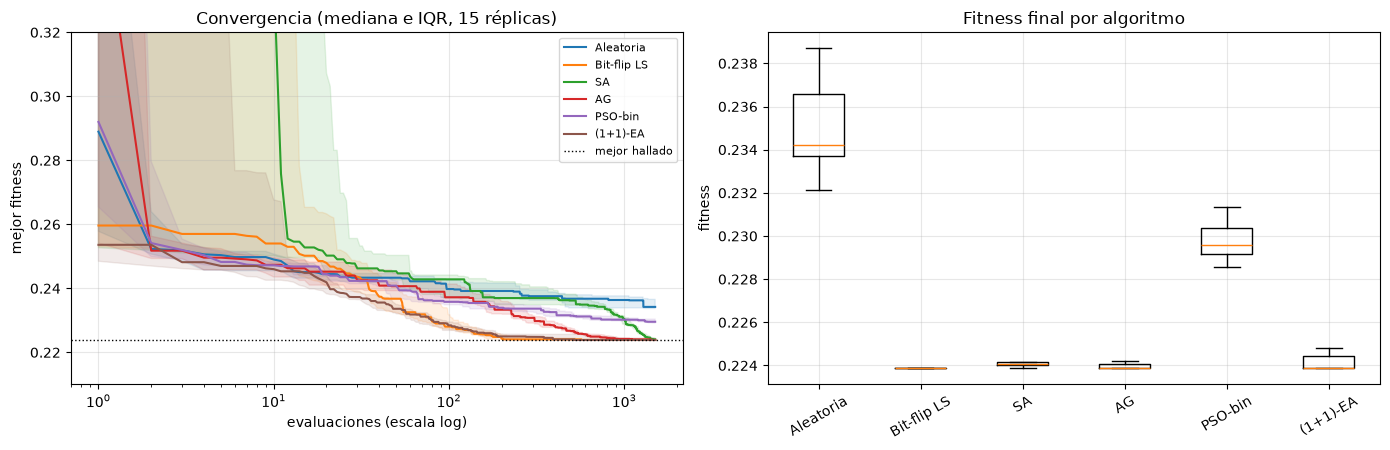

Kruskal-Wallis (fitness final): H=72.83, p=2.63e-14
  algoritmo mediana mediana_Aleatoria       p  p_Holm
Bit-flip LS 0.22387           0.23420 6.9e-07 3.4e-06
         SA 0.22406           0.23420 3.2e-06 9.5e-06
         AG 0.22387           0.23420 2.4e-06 9.5e-06
    PSO-bin 0.22956           0.23420 3.4e-06 9.5e-06
   (1+1)-EA 0.22387           0.23420 2.5e-06 9.5e-06


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for a in ALGOS:
    C = np.array([r["curva"] for r in RES if r["alg"] == a]); x_ = np.arange(1, B + 1)
    ax[0].plot(x_, np.median(C, 0), color=COLORES[a], label=a); ax[0].fill_between(x_, np.percentile(C, 25, 0), np.percentile(C, 75, 0), color=COLORES[a], alpha=0.12)
ax[0].set_ylim(0.21, 0.32); ax[0].set_xscale("log"); ax[0].set_xlabel("evaluaciones (escala log)"); ax[0].set_ylabel("mejor fitness"); ax[0].set_title("Convergencia (mediana e IQR, 15 réplicas)")
mejor_ref = min(r["f"] for r in RES); ax[0].axhline(mejor_ref, color="k", ls=":", lw=1, label="mejor hallado"); ax[0].legend(fontsize=8)
g = [df_res[df_res.alg == a]["f"].values for a in ALGOS]
ax[1].boxplot(g, showfliers=False); ax[1].set_xticks(range(1, len(ALGOS) + 1)); ax[1].set_xticklabels(list(ALGOS), rotation=30)
ax[1].set_title("Fitness final por algoritmo"); ax[1].set_ylabel("fitness")
plt.tight_layout(); plt.show()

# Significancia: Kruskal-Wallis y Mann-Whitney vs búsqueda aleatoria (Holm)
def holm(pv):
    pv = np.asarray(pv); o = np.argsort(pv); m = len(pv); aj = np.empty(m); prev = 0
    for r_, i in enumerate(o): prev = max(prev, min(1.0, (m - r_) * pv[i])); aj[i] = prev
    return aj
print("Kruskal-Wallis (fitness final): H=%.2f, p=%.2e" % stats.kruskal(*g))
otros = [a for a in ALGOS if a != "Aleatoria"]
ps = [stats.mannwhitneyu(df_res[df_res.alg == a]["f"], df_res[df_res.alg == "Aleatoria"]["f"], alternative="two-sided").pvalue for a in otros]
tsig = pd.DataFrame({"algoritmo": otros, "mediana": [df_res[df_res.alg == a]["f"].median() for a in otros],
                     "mediana_Aleatoria": df_res[df_res.alg == "Aleatoria"]["f"].median(), "p": ps, "p_Holm": holm(ps)})
print(tsig.to_string(index=False, formatters={"mediana": "{:.5f}".format, "mediana_Aleatoria": "{:.5f}".format, "p": "{:.1e}".format, "p_Holm": "{:.1e}".format}))

### Estabilidad: frecuencia de selección de cada variable

Para cada variable, ¿en qué fracción de las corridas (de todos los metaheurísticos) fue seleccionada? Una variable *informativa y relevante* debe aparecer casi siempre; el ruido, casi nunca; las redundantes, a veces (sustituibles).

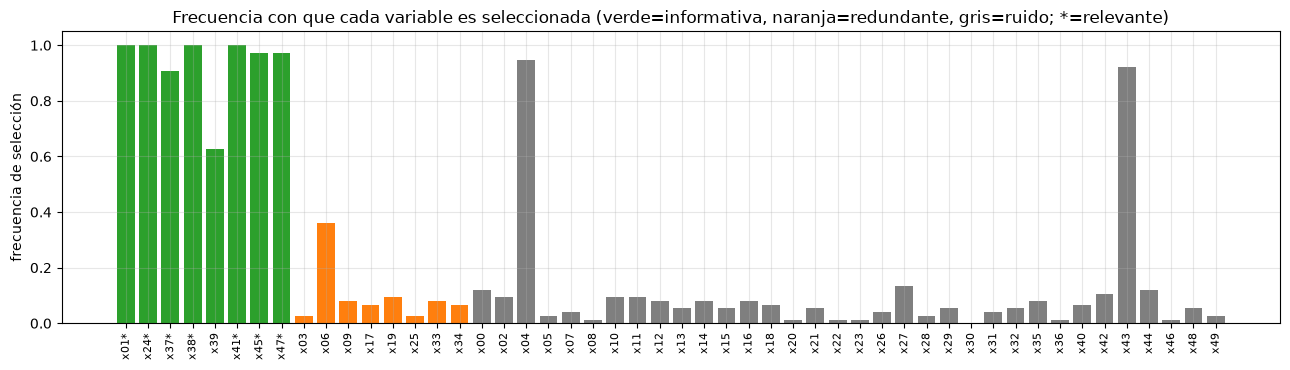

Frecuencia media por tipo: {'informativa': 0.935, 'redundante': 0.1, 'ruido': 0.108}
Frecuencia media de las relevantes: 0.979
Variables de ruido con frecuencia > 0.5: {'x04': 0.95, 'x43': 0.92}
Informativas NO relevantes (aporte < 1%) y su frecuencia: {'x39': 0.63}
Correlación muestral |corr(x, y)| de esas variables de ruido: {'x04': 0.033, 'x43': 0.002}


In [9]:
freq = np.mean([r["x"] for r in RES if r["alg"] != "Aleatoria"], axis=0)
orden = np.argsort([{"informativa": 0, "redundante": 1, "ruido": 2}[t] for t in tipo], kind="stable")
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(range(p), freq[orden], color=[colores[tipo[j]] for j in orden])
ax.set_xticks(range(p)); ax.set_xticklabels([f"{nombres[j]}{'*' if relevante[j] else ''}" for j in orden], rotation=90, fontsize=8)
ax.set_ylabel("frecuencia de selección"); ax.set_title("Frecuencia con que cada variable es seleccionada (verde=informativa, naranja=redundante, gris=ruido; *=relevante)")
plt.tight_layout(); plt.show()
print("Frecuencia media por tipo:", {t: round(float(freq[tipo == t].mean()), 3) for t in ("informativa", "redundante", "ruido")})
print("Frecuencia media de las relevantes:", round(float(freq[relevante].mean()), 3))
print("Variables de ruido con frecuencia > 0.5:", {str(nombres[j]): round(float(freq[j]), 2) for j in np.where((tipo == "ruido") & (freq > 0.5))[0]})
print("Informativas NO relevantes (aporte < 1%) y su frecuencia:", {str(nombres[j]): round(float(freq[j]), 2) for j in np.where((tipo == "informativa") & ~relevante)[0]})
print("Correlación muestral |corr(x, y)| de esas variables de ruido:", {str(nombres[j]): round(float(abs(np.corrcoef(X[:, j], y)[0, 1])), 3) for j in np.where((tipo == "ruido") & (freq > 0.5))[0]})

**Lectura.** Las variables informativas relevantes casi siempre son seleccionadas; las redundantes aparecen poco. Lo más instructivo está en el ruido: la mayoría de las variables de ruido casi nunca entra, pero **una o dos variables de ruido son elegidas en casi todas las corridas** (ver la impresión). No es inestabilidad del optimizador (todos coinciden), sino **sobreajuste de la selección**: en esta muestra finita esas variables reducen el error de validación cruzada por coincidencia muestral, aunque su correlación *marginal* con $y$ sea casi nula (ver impresión): actúan en conjunto con otras variables (algo que un filtro univariante no puede ver, pero un wrapper sí), y un wrapper que optimiza ese error las incorpora de forma consistente. La variable informativa de aporte marginal (<1% de la varianza) queda en una zona intermedia: a veces entra, a veces no. Un conjunto de prueba independiente (o *stability selection*, ejercicio 4) es la forma de distinguir señal débil de coincidencia.

## 8. Frente de Pareto: precisión vs parsimonia

La penalización escalariza un problema bi-objetivo: minimizar el **error** y minimizar el **número de variables** $k$. Cada evaluación que hicieron los optimizadores es un punto $(k,\text{err})$; el **frente de Pareto** son los puntos no dominados (ningún otro tiene a la vez $\le k$ y $\le$ error, con alguna desigualdad estricta). Es el catálogo de "mejor error disponible con $k$ variables"; el peso $\lambda$ escoge un punto de él (el que minimiza $\text{err}+\lambda k/p$: el punto de contacto con una recta de pendiente $-\lambda/p$).

Tamaño del subconjunto óptimo del escalarizado según lambda (sobre el archivo):
 lambda  k_óptimo_sobre_frente  err_cv
  0.000                     14  0.2191
  0.005                     14  0.2191
  0.010                     12  0.2194
  0.020                     10  0.2199
  0.050                      9  0.2208
  0.100                      8  0.2218
  0.200                      8  0.2218


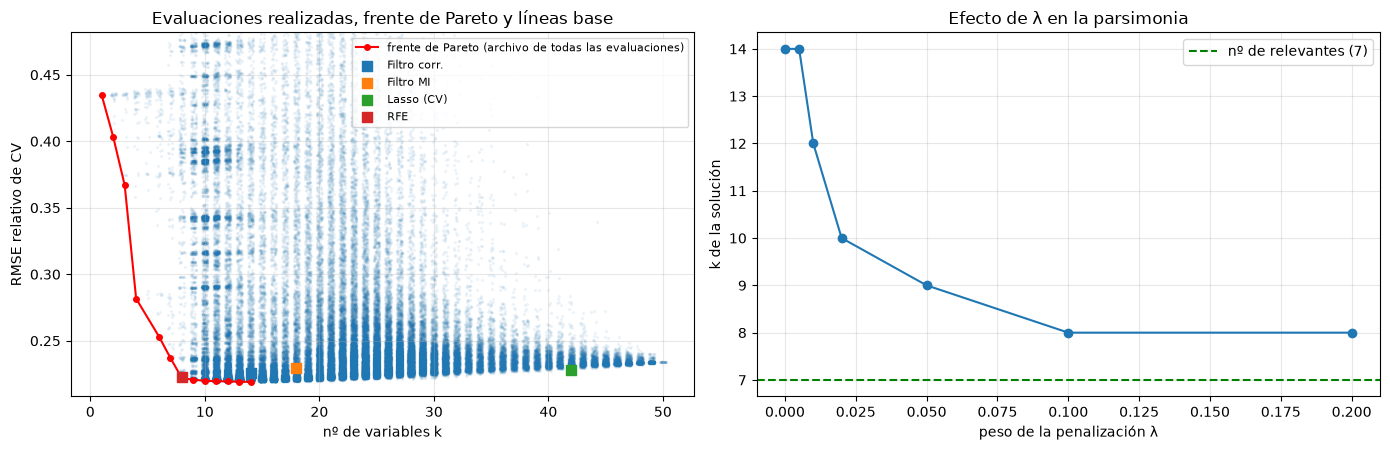

In [10]:
arch = {}                                       # mejor error visto para cada tamaño k (archivo de TODAS las evaluaciones)
for r in RES:
    for k, e in r["archivo"]:
        if k not in arch or e < arch[k]: arch[k] = e
ks = np.array(sorted(arch)); es = np.array([arch[k] for k in ks])
frente = [(k, e) for k, e in zip(ks, es) if not np.any((ks <= k) & (es <= e) & ((ks < k) | (es < e)))]
fk, fe = zip(*frente)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
todos_k = np.concatenate([[k for k, _ in r["archivo"]] for r in RES]); todos_e = np.concatenate([[e for _, e in r["archivo"]] for r in RES])
ax[0].scatter(todos_k + np.random.default_rng(0).uniform(-0.25, 0.25, len(todos_k)), todos_e, s=2, alpha=0.05, color="tab:blue")
ax[0].plot(fk, fe, "r-o", ms=4, label="frente de Pareto (archivo de todas las evaluaciones)")
for n_, m_ in base.items():
    ax[0].scatter(m_.sum(), W_iid.error(m_), marker="s", s=60, label=n_, zorder=5)
ax[0].set_ylim(min(fe) * 0.95, min(fe) * 2.2); ax[0].set_xlabel("nº de variables k"); ax[0].set_ylabel("RMSE relativo de CV")
ax[0].set_title("Evaluaciones realizadas, frente de Pareto y líneas base"); ax[0].legend(fontsize=8)

# efecto de lambda: la solución óptima del escalarizado se mueve sobre el frente
lams = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
filas = []
for lam in lams:
    j = int(np.argmin([e + lam * k / p for k, e in zip(ks, es)])); filas.append({"lambda": lam, "k_óptimo_sobre_frente": int(ks[j]), "err_cv": es[j]})
tl = pd.DataFrame(filas); print("Tamaño del subconjunto óptimo del escalarizado según lambda (sobre el archivo):"); print(tl.round(4).to_string(index=False))
ax[1].plot(tl["lambda"], tl["k_óptimo_sobre_frente"], "o-"); ax[1].axhline(relevante.sum(), color="g", ls="--", label=f"nº de relevantes ({relevante.sum()})")
ax[1].set_xlabel("peso de la penalización λ"); ax[1].set_ylabel("k de la solución"); ax[1].set_title("Efecto de λ en la parsimonia"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura.** (i) Los puntos azules son las evaluaciones de todas las corridas: la nube cubre casi todos los tamaños (la búsqueda aleatoria y el PSO exploran ampliamente, los métodos locales se concentran en la zona de buen error) y el **frente de Pareto** (línea roja) baja con $k$ y se aplana cerca del número de variables relevantes. (ii) Las líneas base son puntos del plano $(k,\text{err})$: RFE queda sobre el frente o muy cerca, mientras que los filtros y Lasso, que están más a la derecha con error igual o mayor, están **dominados** (existe un subconjunto con menos variables y error menor o igual). (iii) El panel derecho muestra que $\lambda$ controla dónde se corta el frente: con $\lambda$ pequeño la solución usa más variables (incluye redundantes y ruido que marginalmente ayudan) y al crecer $\lambda$ el tamaño disminuye hasta estabilizarse cerca del número de relevantes. Elegir $\lambda$ es una decisión de negocio sobre cuánto error se cambia por una variable menos.

## 9. Aplicación a la serie de demanda eléctrica con rezagos candidatos

Volvemos a la serie horaria sintética de la [notebook 16](16-hiperparametros-ml-metaheuristicas.ipynb) (se regenera aquí con la misma receta, para que esta notebook sea autocontenida). Ahora la pregunta es: *de un catálogo de 29 variables candidatas, ¿cuáles hacen falta para pronosticar la demanda a un día de antelación?* El catálogo mezcla:

| Tipo | Variables | Papel en la verdad |
|---|---|---|
| **Generativas** | armónicos de la hora (1.º y 2.º), `finde`, `lunes`, `festivo`, grados de enfriamiento (`cdd`) y calefacción (`hdd`), `t` (tendencia) | Son los términos con los que se construyó $y_t$ |
| **Proxies** | `dow_sin/cos`, `temp`, `temp²`, `temp_lag24`, rezagos de demanda a 24, 48, 72, 96, 120, 144, 168 y 336 h | Contienen información *redundante* o parcial sobre lo generativo |
| **Ruido** | 6 variables aleatorias | No aportan nada |

La validación es **temporal**: pliegues de ventana creciente (se entrena con el pasado y se valida en el bloque siguiente) y un bloque final de prueba intacto. Como las variables generativas son *exactamente* los términos del proceso, esperamos que el wrapper las prefiera a rezagos y ruido, pero la redundancia de los rezagos con el calendario hace que el problema no sea trivial.

In [11]:
def generar_demanda(dias=190, seed=0):
    rng = np.random.default_rng(seed); n = dias * 24
    idx = pd.date_range("2023-01-01", periods=n, freq="h")
    h, dow, doy = idx.hour.values, idx.dayofweek.values, idx.dayofyear.values
    ar = np.zeros(n)
    for t in range(1, n): ar[t] = 0.995 * ar[t - 1] + rng.normal(0, 0.35)
    temp = 22 + 3 * np.sin(2 * np.pi * (doy - 100) / 365) + 4 * np.sin(2 * np.pi * (h - 9) / 24) + ar
    festivo = np.zeros(n, bool)
    for d in rng.choice(np.arange(dias), size=max(3, dias // 25), replace=False): festivo[d * 24:(d + 1) * 24] = True
    tend = 1000 * (1 + 0.0003 * np.arange(n) / 24)
    diario = 120 * np.sin(2 * np.pi * (h - 14) / 24) + 80 * np.sin(4 * np.pi * (h - 5) / 24)
    semanal = np.where(dow >= 5, -110, 0) + np.where(dow == 0, -20, 0)
    clima = 9.0 * np.maximum(temp - 24, 0) ** 1.3 + 2.0 * np.maximum(18 - temp, 0) ** 1.5
    ruido = np.zeros(n)
    for t in range(1, n): ruido[t] = 0.8 * ruido[t - 1] + rng.normal(0, 8)
    y = tend + diario + semanal + clima + np.where(festivo, -140, 0) + ruido
    return pd.DataFrame({"demanda": y, "temp": temp, "festivo": festivo.astype(int)}, index=idx)

def catalogo(df, seed=0):
    rng = np.random.default_rng(seed)
    h, dow = df.index.hour.values, df.index.dayofweek.values; T = df["temp"].values; n = len(df)
    C = {}; tipos = {}
    def add(nombre, v, t): C[nombre] = np.asarray(v, float); tipos[nombre] = t
    add("h1_sin", np.sin(2 * np.pi * h / 24), "generativa"); add("h1_cos", np.cos(2 * np.pi * h / 24), "generativa")
    add("h2_sin", np.sin(4 * np.pi * h / 24), "generativa"); add("h2_cos", np.cos(4 * np.pi * h / 24), "generativa")
    add("finde", dow >= 5, "generativa"); add("lunes", dow == 0, "generativa"); add("festivo", df["festivo"].values, "generativa")
    add("cdd", np.maximum(T - 24, 0) ** 1.3, "generativa"); add("hdd", np.maximum(18 - T, 0) ** 1.5, "generativa")
    add("t", np.arange(n) / n, "generativa")
    add("dow_sin", np.sin(2 * np.pi * dow / 7), "proxy"); add("dow_cos", np.cos(2 * np.pi * dow / 7), "proxy")
    add("temp", T, "proxy"); add("temp2", (T - T.mean()) ** 2, "proxy"); add("temp_lag24", pd.Series(T).shift(24).values, "proxy")
    for L in (24, 48, 72, 96, 120, 144, 168, 336): add(f"lag_{L}", df["demanda"].shift(L).values, "proxy")
    for j in range(6): add(f"ruido_{j}", rng.normal(size=n), "ruido")
    M = pd.DataFrame(C, index=df.index).iloc[336:]
    return M, df["demanda"].iloc[336:], np.array([tipos[c] for c in M.columns])

df_d = generar_demanda(190, seed=2024)
Md, yd_s, tipo_d = catalogo(df_d)
Xd, yd = Md.values, yd_s.values
pd_ = Xd.shape[1]; nom_d = np.array(Md.columns)
N_SEL = 3500                                      # selección (validación temporal) ; el resto = prueba intacta
pliegues_t = [(np.arange(0, s), np.arange(s, s + 500)) for s in (1500, 2000, 2500, 3000)]
W_t = Wrapper(Xd[:N_SEL], yd[:N_SEL], pliegues_t, lam=0.02)
print(f"Catálogo: {pd_} variables | filas: {len(yd)} (selección={N_SEL}, prueba={len(yd) - N_SEL})")
print("Por tipo:", dict(pd.Series(tipo_d).value_counts()))
gen_d = tipo_d == "generativa"

def mape(y, p_): return 100 * np.mean(np.abs((y - p_) / y))
def resumen_demanda(mask):
    S = np.flatnonzero(mask); mu, sd = Xd[:N_SEL][:, S].mean(0), Xd[:N_SEL][:, S].std(0) + 1e-12
    m = Ridge(alpha=W_t.alpha).fit((Xd[:N_SEL][:, S] - mu) / sd, yd[:N_SEL])
    pr = m.predict((Xd[N_SEL:][:, S] - mu) / sd)
    return {"k": int(mask.sum()), "generativas": int(mask[gen_d].sum()), "proxies": int(mask[tipo_d == "proxy"].sum()),
            "ruido": int(mask[tipo_d == "ruido"].sum()), "fitness_cv": W_t.fitness(mask), "MAPE_test": mape(yd[N_SEL:], pr)}

Catálogo: 29 variables | filas: 4224 (selección=3500, prueba=724)
Por tipo: {'proxy': np.int64(13), 'generativa': np.int64(10), 'ruido': np.int64(6)}


In [12]:
Bd, Rd = 1500, 10
t0 = time.perf_counter()
RES_D = [ejecutar(a, W_t, Bd, s) for a in ALGOS for s in range(Rd)]
print(f"{len(RES_D)} corridas en {time.perf_counter() - t0:.0f}s")
filas = []
for r in RES_D:
    d = resumen_demanda(r["x"]); d.update(alg=r["alg"], f=r["f"]); filas.append(d)
dd = pd.DataFrame(filas)
tabla_d = dd.groupby("alg", sort=False).agg(fitness_med=("f", "median"), k_med=("k", "median"), generativas=("generativas", "mean"),
                                            proxies=("proxies", "mean"), ruido=("ruido", "mean"), MAPE_test=("MAPE_test", "mean"))
base_d = {"Filtro corr.": base_correlacion(Xd[:N_SEL], yd[:N_SEL], W_t)[0], "Filtro MI": base_mi(Xd[:N_SEL], yd[:N_SEL], W_t)[0],
          "Lasso (CV)": base_lasso(Xd[:N_SEL], yd[:N_SEL], W_t)[0], "RFE": base_rfe(Xd[:N_SEL], yd[:N_SEL], W_t)[0],
          "Todas (29)": np.ones(pd_, np.int8), "Solo generativas": gen_d.astype(np.int8)}
tb = pd.DataFrame({n: resumen_demanda(m) for n, m in base_d.items()}).T
print(f"Metaheurísticas (B={Bd}, {Rd} réplicas) - la columna 'generativas' es sobre un total de {gen_d.sum()}:")
print(tabla_d.round(4).sort_values("fitness_med").to_string())
print("\nLíneas base:"); print(tb.round(4).to_string())

60 corridas en 9s


Metaheurísticas (B=1500, 10 réplicas) - la columna 'generativas' es sobre un total de 10:
             fitness_med  k_med  generativas  proxies  ruido  MAPE_test
alg                                                                    
Bit-flip LS       0.1187   11.0         10.0      1.0    0.0     1.1133
SA                0.1187   11.0         10.0      1.0    0.0     1.1133
AG                0.1187   11.0         10.0      1.0    0.0     1.1127
(1+1)-EA          0.1187   11.0         10.0      1.0    0.0     1.1133
PSO-bin           0.1220   14.0          9.8      2.3    1.8     1.1107
Aleatoria         0.1280   20.0          9.8      6.7    3.8     1.1051

Líneas base:
                     k  generativas  proxies  ruido  fitness_cv  MAPE_test
Filtro corr.      21.0          9.0     12.0    0.0      0.1319     1.1401
Filtro MI         21.0          9.0     12.0    0.0      0.1319     1.1401
Lasso (CV)        28.0         10.0     12.0    6.0      0.1354     1.1070
RFE               10

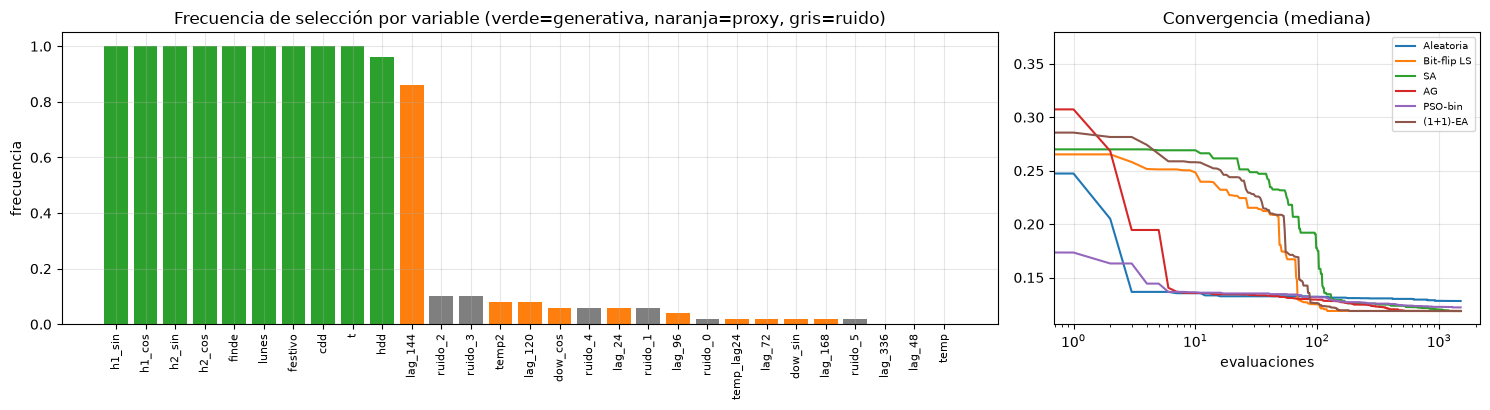

Frecuencia media por tipo: {'generativa': 0.996, 'proxy': 0.097, 'ruido': 0.06}
Variables con frecuencia >= 0.8: ['h1_sin (generativa)', 'h1_cos (generativa)', 'h2_sin (generativa)', 'h2_cos (generativa)', 'finde (generativa)', 'lunes (generativa)', 'festivo (generativa)', 'cdd (generativa)', 't (generativa)', 'hdd (generativa)', 'lag_144 (proxy)']
Variables generativas con frecuencia < 0.5: []


In [13]:
freq_d = np.mean([r["x"] for r in RES_D if r["alg"] != "Aleatoria"], axis=0)
orden = np.argsort(-freq_d)
colores_d = {"generativa": "tab:green", "proxy": "tab:orange", "ruido": "tab:gray"}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].bar(range(pd_), freq_d[orden], color=[colores_d[tipo_d[j]] for j in orden])
ax[0].set_xticks(range(pd_)); ax[0].set_xticklabels(nom_d[orden], rotation=90, fontsize=8)
ax[0].set_title("Frecuencia de selección por variable (verde=generativa, naranja=proxy, gris=ruido)"); ax[0].set_ylabel("frecuencia")
for a in ALGOS:
    C = np.array([r["curva"] for r in RES_D if r["alg"] == a]); ax[1].plot(np.median(C, 0), color=COLORES[a], label=a)
ax[1].set_xscale("log"); ax[1].set_title("Convergencia (mediana)"); ax[1].set_xlabel("evaluaciones"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Frecuencia media por tipo:", {t: round(float(freq_d[tipo_d == t].mean()), 3) for t in ("generativa", "proxy", "ruido")})
print("Variables con frecuencia >= 0.8:", [f"{nom_d[j]} ({tipo_d[j]})" for j in orden if freq_d[j] >= 0.8])
print("Variables generativas con frecuencia < 0.5:", [f"{nom_d[j]}={freq_d[j]:.2f}" for j in np.where(gen_d & (freq_d < 0.5))[0]])

**Lectura.** Sobre la serie de demanda, los wrappers recuperan las variables generativas (armónicos de la hora, fin de semana, lunes, festivo, grados de enfriamiento/calefacción y tendencia) casi siempre, y descartan el ruido y casi todos los rezagos y proxies, que son *redundantes* una vez se conocen los calendarios y la temperatura (la excepción más frecuente es un rezago largo, `lag_144`, que aparece en la mayoría de las corridas como complemento marginal). Dos matices importantes:

- Pasar de 29 variables a unas 10-11 **no cuesta precisión medible en prueba**: el MAPE de prueba es prácticamente el mismo con todas las variables, con el subconjunto de los wrappers o con solo las generativas (la diferencia está dentro del ruido). La ganancia de la selección aquí es **parsimonia e interpretabilidad**, no exactitud.
- Los filtros (correlación e información mutua) eligen 21 variables, muchas de ellas proxies redundantes, y aun así dejan fuera alguna generativa: ejemplo concreto de por qué un filtro univariante no es una buena estrategia con variables fuertemente colineales (los rezagos).

## 10. Selección simultánea de características e hiperparámetros (individuo mixto)

Seleccionar variables y ajustar hiperparámetros **por separado** (primero una, luego la otra) ignora su interacción: el subconjunto óptimo depende del modelo y la configuración óptima del modelo depende del subconjunto. Un individuo **mixto** codifica ambas cosas a la vez:

$$
z=(\underbrace{x_1,\dots,x_p}_{\text{bits}},\ \underbrace{u_1,\dots,u_4}_{\text{hiperparámetros en }[0,1]}),\qquad F(z)=\text{err}_{\text{val}}\big(\mathcal{A}_{\lambda(u)}[\,:,S_x]\big)+\lambda\tfrac{\lVert x\rVert_1}{p}.
$$

Los operadores respetan el tipo de cada bloque: **cruce uniforme** sobre todo el individuo; **mutación** por inversión de bit en la parte binaria y **gaussiana** en la parte continua. El modelo ahora es un `HistGradientBoostingRegressor` (no lineal, más caro: decenas de milisegundos por evaluación), con hiperparámetros `max_iter`$\in[20,60]$, `max_depth`$\in[2,6]$, `learning_rate`$\in[0.03,0.3]$ (log) y `min_samples_leaf`$\in[10,80]$. El presupuesto es de $B_m=100$ evaluaciones, y se comparan:

| Estrategia | Descripción |
|---|---|
| **A. Fijo** | Todas las variables, hiperparámetros razonables fijados a mano (`max_iter`=60, `max_depth`=4, `learning_rate`=0.1, `min_samples_leaf`=30) |
| **B. Solo HP** | Todas las variables; $(1+1)$-ES sobre los 4 hiperparámetros con $B_m$ evaluaciones |
| **C. Dos etapas** | Máscara del wrapper Ridge de la sección 9 (barata), luego $(1+1)$-ES sobre hiperparámetros con $B_m$ evaluaciones |
| **D. Conjunta** | AG de estado estable sobre el individuo mixto, con $B_m$ evaluaciones |

Se usa una sola partición temporal (2/3 entrenamiento, 1/3 validación dentro del bloque de selección) y el bloque final de prueba para la evaluación imparcial.

In [14]:
class WrapperMixto:
    """Fitness de (máscara, hiperparámetros): GBR sobre el subconjunto, RMSE relativo de validación + lambda*k/p."""
    def __init__(self, Xm, ym, n_tr, lam=0.02):
        self.X, self.y, self.n_tr, self.lam, self.p = Xm, ym, n_tr, lam, Xm.shape[1]
    @staticmethod
    def hp(u):
        return {"max_iter": int(round(20 + u[0] * 40)), "max_depth": int(round(2 + u[1] * 4)),
                "learning_rate": float(np.exp(np.log(0.03) + u[2] * (np.log(0.3) - np.log(0.03)))),
                "min_samples_leaf": int(round(10 + u[3] * 70))}
    def _fit(self, mask, u, tr, te):
        S = np.flatnonzero(mask)
        m = HistGradientBoostingRegressor(random_state=0, **self.hp(u)).fit(self.X[tr][:, S], self.y[tr])
        return m.predict(self.X[te][:, S])
    def error(self, mask, u):
        tr, va = np.arange(self.n_tr), np.arange(self.n_tr, len(self.y))
        return float(np.sqrt(np.mean((self.y[va] - self._fit(mask, u, tr, va)) ** 2)) / self.y.std())
    def fitness(self, mask, u): return self.error(mask, u) + self.lam * mask.sum() / self.p

class EvalMixto:
    def __init__(self, w, B): self.w, self.B, self.cache, self.usado, self.llamadas, self.mejor = w, B, {}, 0, 0, (np.inf, None, None)
    def __call__(self, mask, u):
        if self.usado >= self.B or self.llamadas > 80 * self.B: raise Agotado
        self.llamadas += 1
        key = (np.asarray(mask, np.int8).tobytes(), tuple(np.round(u, 2)))              # los HP se redondean a 0.01: identidad efectiva
        if key in self.cache: return self.cache[key]
        f = self.w.fitness(mask, u); self.cache[key] = f; self.usado += 1
        if f < self.mejor[0]: self.mejor = (f, np.asarray(mask).copy(), np.asarray(u).copy())
        return f

def es_hp(ev, rng, mask, sigma=0.2):
    u = rng.random(4); f = ev(mask, u)
    while True:
        v = np.clip(u + sigma * rng.normal(size=4) * (rng.random(4) < 0.5), 0, 1)
        fv = ev(mask, v)
        if fv <= f: u, f = v, fv

def ga_mixto(ev, rng, p, mu=12, pm=None):
    pm = 1.5 / p if pm is None else pm
    M = np.array([mascara_aleatoria(rng, p, dens=0.5) for _ in range(mu)]); U = rng.random((mu, 4))
    fit = np.array([ev(M[i], U[i]) for i in range(mu)])
    while True:
        def torneo():
            c = rng.choice(mu, 3, replace=False); return c[np.argmin(fit[c])]
        a, b = torneo(), torneo()
        sel = rng.random(p) < 0.5; hm = np.where(sel, M[a], M[b]).astype(np.int8)
        selu = rng.random(4) < 0.5; hu = np.where(selu, U[a], U[b])
        hm = np.where(rng.random(p) < pm, 1 - hm, hm).astype(np.int8)
        hu = np.clip(hu + 0.15 * rng.normal(size=4) * (rng.random(4) < 0.3), 0, 1)
        if hm.sum() == 0: hm[rng.integers(p)] = 1
        for _ in range(5):                                                       # memoria: evitar duplicados
            if (hm.tobytes(), tuple(np.round(hu, 2))) not in ev.cache: break
            hm[rng.integers(p)] ^= 1
            if hm.sum() == 0: hm[rng.integers(p)] = 1
        fh = ev(hm, hu); j = int(np.argmax(fit))
        if fh < fit[j]: M[j], U[j], fit[j] = hm, hu, fh

WM = WrapperMixto(Xd[:N_SEL], yd[:N_SEL], n_tr=2300, lam=0.02)
def prueba_mixta(mask, u):
    S = np.flatnonzero(mask)
    m = HistGradientBoostingRegressor(random_state=0, **WM.hp(u)).fit(Xd[:N_SEL][:, S], yd[:N_SEL])
    return mape(yd[N_SEL:], m.predict(Xd[N_SEL:][:, S]))

Bm, Rm = 100, 3
mask_ridge = np.median([r["x"] for r in RES_D if r["alg"] == "AG"], axis=0).round().astype(np.int8)   # máscara consenso del AG (sección 9)
u_def = np.array([1.0, 0.5, (np.log(0.1) - np.log(0.03)) / (np.log(0.3) - np.log(0.03)), 20 / 70])   # max_iter=60, depth=4, lr=0.1, hoja=30
todas_m = np.ones(pd_, np.int8)
t0 = time.perf_counter(); filas = []; sel_D = []
fA = WM.fitness(todas_m, u_def); filas.append({"estrategia": "A. Fijo (a mano)", "semilla": 0, "fitness_val": fA, "k": pd_, "MAPE_test": prueba_mixta(todas_m, u_def)})
for s in range(Rm):
    for nombre in ("B. Solo HP", "C. Dos etapas", "D. Conjunta"):
        ev = EvalMixto(WM, Bm); rng = np.random.default_rng(500 + s)
        try:
            if nombre.startswith("B"): es_hp(ev, rng, todas_m)
            elif nombre.startswith("C"): es_hp(ev, rng, mask_ridge)
            else: ga_mixto(ev, rng, pd_)
        except Agotado: pass
        f, m_, u_ = ev.mejor
        if nombre.startswith("D"): sel_D.append(nom_d[m_ == 1].tolist())
        filas.append({"estrategia": nombre, "semilla": s, "fitness_val": f, "k": int(m_.sum()), "MAPE_test": prueba_mixta(m_, u_)})
print(f"Experimento mixto: {time.perf_counter() - t0:.0f}s | máscara consenso de la etapa 1 (AG-Ridge): k={mask_ridge.sum()}")
mix = pd.DataFrame(filas)
print("Variables elegidas por la estrategia D (primera réplica):", sel_D[0])
print("Máscara consenso del wrapper Ridge (etapa 1 de C):", nom_d[mask_ridge == 1].tolist())
print("En el wrapper lineal y NO en la solución conjunta:", sorted(set(nom_d[mask_ridge == 1]) - set(sel_D[0])))
print("En la solución conjunta y NO en el wrapper lineal:", sorted(set(sel_D[0]) - set(nom_d[mask_ridge == 1])))
print(mix.groupby("estrategia").agg(fitness_val=("fitness_val", "mean"), k=("k", "mean"), MAPE_test=("MAPE_test", "mean"), MAPE_test_std=("MAPE_test", "std")).round(4).to_string())

Experimento mixto: 24s | máscara consenso de la etapa 1 (AG-Ridge): k=11
Variables elegidas por la estrategia D (primera réplica): ['h1_sin', 'h1_cos', 'h2_sin', 'lunes', 'festivo', 'dow_sin', 'dow_cos', 'temp', 'temp2', 'temp_lag24', 'lag_24', 'lag_72', 'lag_96', 'lag_144', 'ruido_2', 'ruido_3']
Máscara consenso del wrapper Ridge (etapa 1 de C): ['h1_sin', 'h1_cos', 'h2_sin', 'h2_cos', 'finde', 'lunes', 'festivo', 'cdd', 'hdd', 't', 'lag_144']
En el wrapper lineal y NO en la solución conjunta: ['cdd', 'finde', 'h2_cos', 'hdd', 't']
En la solución conjunta y NO en el wrapper lineal: ['dow_cos', 'dow_sin', 'lag_24', 'lag_72', 'lag_96', 'ruido_2', 'ruido_3', 'temp', 'temp2', 'temp_lag24']
                  fitness_val        k  MAPE_test  MAPE_test_std
estrategia                                                      
A. Fijo (a mano)       0.3262  29.0000     2.9035            NaN
B. Solo HP             0.3154  29.0000     2.6110         0.1746
C. Dos etapas          0.3136  11.0000     2

**Lectura.** (Con solo 3 réplicas por estrategia estos resultados son *indicativos*; compara la diferencia de medias con la desviación entre réplicas.)

- Ajustar solo los hiperparámetros (B) o seleccionar variables con un modelo distinto del final (C) mejora sobre la configuración fija (A), pero la estrategia **conjunta (D)** obtiene el menor error de validación y, en promedio, el menor error de prueba con el mismo presupuesto.
- La máscara elegida por D **difiere** de la del wrapper lineal (ver las listas impresas): lo que es óptimo para Ridge no lo es para un modelo de árboles. Hipótesis: los árboles no extrapolan, así que variables que sirven a un modelo lineal para modelar la tendencia y los efectos climáticos suavemente (`t`, `cdd`, `hdd`) pueden no aportar a un boosting, que se apoya más en los rezagos y en la temperatura directa. (El ejercicio 7 invita a verificarlo.)
- El costo de D es un espacio mayor ($2^{29}\times$ el espacio de hiperparámetros) y evaluaciones ~100 veces más caras que las de Ridge, por lo que la selección exhaustiva ni siquiera es una opción: aquí el presupuesto $B_m$ es la restricción fundamental, igual que en la notebook 16.

## 11. Ventajas, limitaciones, resumen, ejercicios y referencias

### Ventajas y limitaciones de los *wrappers* metaheurísticos

| | Ventajas | Limitaciones |
|---|---|---|
| **Wrapper con metaheurística** | Optimiza la métrica real con el modelo real; maneja redundancia e interacciones; el costo se controla con el presupuesto; permite penalizar lo que se quiera (tamaño, costo de medir una variable) | Costoso con modelos caros; sensible al peso $\lambda$ y a los parámetros del optimizador; sobreajuste al conjunto de validación; resultados no únicos (variables redundantes intercambiables) |
| **Filtros** | Instantáneos, independientes del modelo | No ven redundancia ni interacciones; $k$ se elige aparte |
| **Lasso / embebidos** | Una sola corrida, estables | Sesgo hacia el modelo lineal; con variables muy correlacionadas elige una arbitrariamente |
| **RFE** | Considera el efecto conjunto de las variables restantes | Voraz (no deshace eliminaciones); costo $O(p)$ ajustes |

### Resumen

- Seleccionar variables es optimización **binaria**; el vecindario *bit-flip* tiene $p$ vecinos y el espacio $2^p$ solo permite búsqueda exhaustiva para $p\lesssim 20$: ahí sirve como **verificación** de las metaheurísticas.
- El fitness **error + $\lambda\,k/p$** escalariza un problema bi-objetivo; el **frente de Pareto** de $(k,\text{err})$ muestra el costo de cada variable y el peso $\lambda$ escoge un punto de él.
- Con verdad conocida se puede medir la **recuperación**: relevantes seleccionadas, ruido colado y estabilidad entre corridas; las variables redundantes son intercambiables, por lo que la comparación debe tolerarlas.
- La selección debe hacerse con **validación temporal** (en series) y un **bloque de prueba intacto**; la selección con todos los datos y luego validación produce optimismo.
- Un individuo **mixto** (bits + hiperparámetros) permite optimizar ambos a la vez, a costa de un espacio mayor y evaluaciones más caras: conviene comparar contra el esquema de dos etapas con el mismo presupuesto.

Cierre del repositorio: de vuelta al [índice de notebooks](../../README.md), o repasa [16 · hiperparámetros con metaheurísticas](16-hiperparametros-ml-metaheuristicas.ipynb).

### Ejercicios propuestos

1. **Peso de la penalización.** Repite el experimento con $\lambda\in\{0,0.005,0.02,0.1\}$. Para cada uno, mide recall de relevantes y ruido colado. ¿Qué $\lambda$ recupera mejor la verdad?
2. **Penalización por costo de medición.** Asigna un costo distinto $c_j$ a cada variable (p. ej. un sensor caro) y minimiza $\text{err}+\lambda\sum_j c_jx_j$. ¿Cambia el subconjunto?
3. **Más ruido, más variables.** Sube a $p=100$ con 90 variables de ruido. ¿Cómo cambia la tasa de acierto de cada algoritmo con $B$ fijo? (La búsqueda exhaustiva ya no existe como referencia.)
4. **Estabilidad de selección.** Implementa *stability selection*: ejecuta el optimizador sobre submuestras *bootstrap* y retén las variables con frecuencia $\ge 0.8$.
5. **Operadores.** Cambia el cruce uniforme por cruce de un punto y mide su efecto. ¿Por qué el orden de las columnas importa solo para el segundo?
6. **Multiobjetivo.** Reemplaza la escalarización por [NSGA-II](../04-topicos-avanzados/12-optimizacion-multiobjetivo.ipynb) sobre $(k,\text{err})$ y compara el frente obtenido con el del archivo de la sección 8.
7. **Modelo no lineal.** Repite la sección 7 con un modelo no lineal (gradient boosting) y compara con la selección por importancias del propio modelo.

### Referencias

- Guyon, I. y Elisseeff, A. (2003). *An Introduction to Variable and Feature Selection.* Journal of Machine Learning Research, 3, 1157-1182.
- Kohavi, R. y John, G. H. (1997). *Wrappers for Feature Subset Selection.* Artificial Intelligence, 97(1-2), 273-324.
- Kennedy, J. y Eberhart, R. C. (1997). *A Discrete Binary Version of the Particle Swarm Algorithm.* IEEE International Conference on Systems, Man, and Cybernetics.
- Siedlecki, W. y Sklansky, J. (1989). *A Note on Genetic Algorithms for Large-Scale Feature Selection.* Pattern Recognition Letters, 10(5), 335-347.
- Tibshirani, R. (1996). *Regression Shrinkage and Selection via the Lasso.* Journal of the Royal Statistical Society B, 58(1), 267-288.
- Guyon, I., Weston, J., Barnhill, S. y Vapnik, V. (2002). *Gene Selection for Cancer Classification using Support Vector Machines.* Machine Learning, 46 (RFE).
- Ambroise, C. y McLachlan, G. J. (2002). *Selection Bias in Gene Extraction on the Basis of Microarray Gene-Expression Data.* PNAS, 99(10) (sobre fuga de información al seleccionar variables).
- Meinshausen, N. y Bühlmann, P. (2010). *Stability Selection.* Journal of the Royal Statistical Society B, 72(4).
- Kraskov, A., Stögbauer, H. y Grassberger, P. (2004). *Estimating Mutual Information.* Physical Review E, 69 (base del estimador de información mutua por vecinos).
- Deb, K., Pratap, A., Agarwal, S. y Meyarivan, T. (2002). *A Fast and Elitist Multiobjective Genetic Algorithm: NSGA-II.* IEEE Transactions on Evolutionary Computation, 6(2).